# Amazon drought end of 2023

In [1]:
import matplotlib.pyplot as plt
import matplotlib.colors as colors
import cmocean
from matplotlib.colors import BoundaryNorm
from matplotlib.ticker import (MultipleLocator, AutoMinorLocator)
import matplotlib.dates as mdates
from matplotlib.dates import DateFormatter
from mpl_toolkits.basemap import Basemap
from mpl_toolkits.basemap import shiftgrid
import numpy as np
import os
import datetime as dt
import pandas as pd
import geopandas as gpd
import sys
import xclim as xclim
import calendar
import netCDF4 as nc4
import xarray as xr
# create colorscheme
from dateutil import relativedelta
from datetime import timedelta
#xr.set_options(display_expand_attrs=False)

sys.path.insert(0, '..')
sys.path.insert(0, '../..')

/perm/nejk/python-envs/myenv/lib/python3.8/site-packages/pandas/core/computation/expressions.py:20: UserWarning: Pandas requires version '2.7.3' or newer of 'numexpr' (version '2.7.2' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
/usr/local/apps/python3/3.8.8-01/lib/python3.8/site-packages/geopandas/_compat.py:84: UserWarning: The Shapely GEOS version (3.9.1-CAPI-1.14.2) is incompatible with the GEOS version PyGEOS was compiled with (3.10.4-CAPI-1.16.2). Conversions between both will be slow.
  warnings.warn(


In [2]:
from helpers.helpers import plot_spi_timeseries, plot_precip_timeseries, create_diverging_colorscheme, plot_droughtmap
from helpers.helpers_plotting import create_diverging_colorscheme
from helpers.geodata import calculate_gridarea

In [7]:
ipath         = "/scratch/nejk/droughts_hist/"
windows       = [1,3,12]
region        = "south_america"
ref_period    = "1991to2020"
ryyyy_start   = int(ref_period[:4])
ryyyy_end     = int(ref_period[6:11])
print(ryyyy_start)
print(ryyyy_end)
time_period   = "19400101to20231001"

1991
2020


In [14]:
# create colorscheme
spi_levels = [-3, -2, -1.5, -1, -0.1, 0.1, 1, 1.5, 2, 3]
plot_type  = 'pcolormesh'
cmap_spi, clevels = create_diverging_colorscheme("brown_white_green", start_color = (102/255, 51/255, 0), mid_color = (1, 1, 1), end_color = (51/255, 102/255, 0), 
                                                 levels = spi_levels, levels4pcolormesh=True if plot_type == "pcolormesh" else False)
color_list = [colors.rgb2hex(cmap_spi(i)) for i in range(cmap_spi.N)]
#print(color_list)

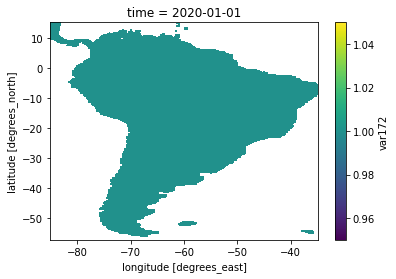

In [4]:
# read landmask
ifile_name    = "landmask_era5_south_america.nc"
ifile         = os.path.join("masks", ifile_name)
varname       = "var172"
landmask = xr.open_dataset(ifile)[varname]
landmask = landmask.where( landmask.values == 1 )
landmask.plot()

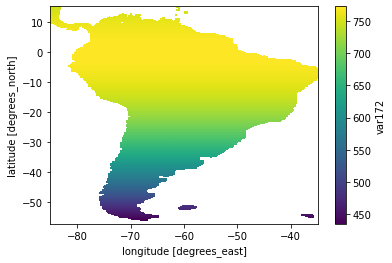

In [5]:
area_2d = calculate_gridarea(landmask.lat, res=abs(landmask.lat[1]-landmask.lat[0]), nlon=len(landmask.lon))*landmask[0,:,:]
area_2d = xr.DataArray(area_2d, coords={'lat': landmask.lat,'lon': landmask.lon}, dims=["lat", "lon"])
area_2d.plot()

In [42]:
# Read drought indicators for different accumulation periods
spi1          = xr.open_dataset(os.path.join(ipath, f"SPI1_gamma_{region}_ref{ref_period}_{time_period}.nc"))[f"SPI1"]
spi1          = spi1.where(spi1 != -9999)
#spi3          = xr.open_dataset(os.path.join(ipath, f"SPI3_gamma_{region}_ref{ref_period}_{time_period}.nc"))[f"SPI3"]
#spi3          = spi3.where(spi3 != -9999)
#spi3          = spi3.sel(time=slice('1960-01-01', '2023-09-01'))
spi12         = xr.open_dataset(os.path.join(ipath, f"SPI12_gamma_{region}_ref{ref_period}_{time_period}.nc"))[f"SPI12"]
spi12         = spi12.where(spi12 != -9999)

# Read drought indicators for different accumulation periods
spei1          = xr.open_dataset(os.path.join(ipath, f"SPEI1_genextreme_{region}_ref{ref_period}_{time_period}.nc"))[f"SPEI1"]
spei1          = spei1.where(spei1 != -9999)
#spei3          = xr.open_dataset(os.path.join(ipath, f"SPEI3_genextreme_{region}_ref{ref_period}_{time_period}.nc"))[f"SPEI3"]
#spei3          = spei3.where(spei3 != -9999)
spei12         = xr.open_dataset(os.path.join(ipath, f"SPEI12_genextreme_{region}_ref{ref_period}_{time_period}.nc"))[f"SPEI12"]
spei12         = spei12.where(spei12 != -9999)

In [43]:
area_3d     = area_2d.expand_dims(dim={"time": spi1.time}, axis=0)
landmask_3d = landmask.reindex_like(spi1, method='nearest')
#to_plot = subregions_landarea['Southwestern Europe'].reindex_like(spi3, method="nearest")
#to_plot.sel(time="2020-08-01").plot()
#print(to_plot.sum(dim=['lat','lon']))

In [44]:
aid_spi1   = {}
aid_spi3   = {}
aid_spi12  = {}
aid_spei1  = {}
aid_spei3  = {}
aid_spei12 = {}

for severity in ['mild','moderate','severe','extreme','any']:

    if severity == "mild":
        thresh_min = -1
        thresh_max = 0
    if severity == "moderate":
        thresh_min = -1.5
        thresh_max = -1
    if severity == "severe":
        thresh_min = -2
        thresh_max = -1.5
    if severity == "extreme":
        thresh_min = -999
        thresh_max = -2
    if severity == "any":
        thresh_min = -999
        thresh_max = 0

    #print(subregions_landarea[iregion].sum(dim=["lat", "lon"]))
    #print(subregions_landarea[iregion].reindex_like(spi3, method="nearest").sum(dim=["lat", "lon"]))

    # SPI
    rspi   = spi1*landmask_3d
    dmask  = xr.where((rspi > thresh_min) & (rspi <= thresh_max), 1, np.nan)
    tmp    = 100 * (dmask*area_3d).sum(dim=["lat", "lon"]) / area_3d.sum(dim=["lat", "lon"])
    aid_spi1[severity] = tmp
    del(tmp, rspi, dmask)
    
    
    rspi   = spi12*landmask_3d
    dmask  = xr.where((rspi > thresh_min) & (rspi <= thresh_max), 1, np.nan)
    tmp    = 100 * (dmask*area_3d).sum(dim=["lat", "lon"]) / area_3d.sum(dim=["lat", "lon"])
    aid_spi12[severity] = tmp
    del(tmp, rspi, dmask)
    
    
    # SPEI
    rspi   = spei12*landmask_3d
    dmask  = xr.where((rspi > thresh_min) & (rspi <= thresh_max), 1, np.nan)
    tmp    = 100 * (dmask*area_3d).sum(dim=["lat", "lon"]) / area_3d.sum(dim=["lat", "lon"])
    aid_spei12[severity] = tmp
    del(tmp, rspi, dmask)
    


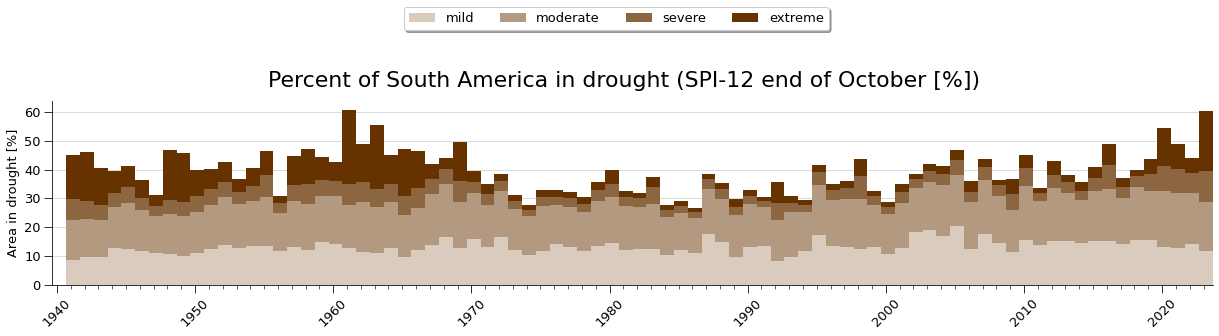

In [45]:
fig, ax1 = plt.subplots(1,1, figsize=(18,4))
fig.suptitle(f"Percent of South America in drought (SPI-12 end of October [%])", fontsize=22)
fig.tight_layout(pad=3.75)
fig.subplots_adjust(top=0.875)
font = {'family' : 'sans-serif',
        'weight' : 'normal',
        'size'   : 13}

plt.rc('font', **font)

severities = ['mild','moderate','severe','extreme']

imonth = 10

pidata1 = aid_spei12['mild'].sel(time=aid_spei12['mild'].time.dt.month.isin([imonth])).to_series()
pidata2 = aid_spei12['moderate'].sel(time=aid_spei12['moderate'].time.dt.month.isin([imonth])).to_series()
pidata3 = aid_spei12['severe'].sel(time=aid_spei12['severe'].time.dt.month.isin([imonth])).to_series()
pidata4 = aid_spei12['extreme'].sel(time=aid_spei12['extreme'].time.dt.month.isin([imonth])).to_series()
apidata = pd.concat([pidata1, pidata2, pidata3, pidata4], axis=1)
apidata.index = apidata.index.shift(-7, freq="MS") # shift datetimeindex to get ticks centered on bar
bottom = np.zeros(len(apidata.index))
for i in apidata.columns:
    p = ax1.bar(apidata[i].index, apidata[i].values, width=relativedelta.relativedelta(months=12), facecolor=color_list[3-i], alpha=1, label=severities[i], bottom=bottom)
    bottom += apidata[i].values
ax1.set_ylabel("Area in drought [%]")
ax1.legend(ncol=4, loc='upper right', bbox_to_anchor=(0.675, 1.55), fancybox=True, shadow=True)
ax1.margins(x=0)
ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)
#ax1.spines['bottom'].set_visible(False)
#ax1.spines['left'].set_visible(False)  
#ax1.tick_params(axis='both', colors='dimgrey')
#ax1.xaxis.label.set_color('dimgrey')
#ax1.yaxis.label.set_color('dimgrey')
#ax1.xaxis.set_minor_locator(MultipleLocator(365)) # does not account for leap years
ax1.xaxis.set_minor_locator(mdates.YearLocator())
ax1.xaxis.set_major_locator(mdates.YearLocator(10))
date_form = DateFormatter("%Y")
ax1.xaxis.set_major_formatter(date_form)
ax1.tick_params(which='minor', length=4)
ax1.tick_params(which='major', length=8)
#ax1.set_xticklabels(ax1.get_xticklabels(), rotation=30, ha='right')
#ax1.grid(True)
ax1.set_axisbelow(True)
ax1.yaxis.grid(color='lightgray', linestyle='solid') #dashed
for tick in ax1.get_xticklabels():
    tick.set_rotation(45)
    

In [52]:
imonth=10
with pd.option_context('display.max_rows', None, 'display.max_columns', None):  # more options can be specified also
    print(aid_spi12['any'].sel(time=aid_spi12['any'].time.dt.month.isin([imonth])).to_series())

time
1940-10-01 06:00:00     0.000000
1941-10-01 06:00:00    57.651646
1942-10-01 06:00:00    57.832553
1943-10-01 06:00:00    49.595038
1944-10-01 06:00:00    46.358404
1945-10-01 06:00:00    51.340875
1946-10-01 06:00:00    49.303391
1947-10-01 06:00:00    38.256462
1948-10-01 06:00:00    50.885379
1949-10-01 06:00:00    55.154948
1950-10-01 06:00:00    53.268362
1951-10-01 06:00:00    51.181981
1952-10-01 06:00:00    57.142125
1953-10-01 06:00:00    46.913857
1954-10-01 06:00:00    53.480253
1955-10-01 06:00:00    65.573617
1956-10-01 06:00:00    39.002295
1957-10-01 06:00:00    55.403162
1958-10-01 06:00:00    58.880171
1959-10-01 06:00:00    61.390730
1960-10-01 06:00:00    52.756739
1961-10-01 06:00:00    76.524235
1962-10-01 06:00:00    63.120979
1963-10-01 06:00:00    65.033473
1964-10-01 06:00:00    61.058453
1965-10-01 06:00:00    63.270600
1966-10-01 06:00:00    61.739017
1967-10-01 06:00:00    58.766639
1968-10-01 06:00:00    64.179036
1969-10-01 06:00:00    66.382513
1970-

Processing SPI-1...


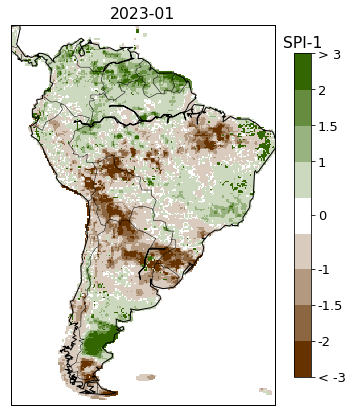

Processing SPI-1...


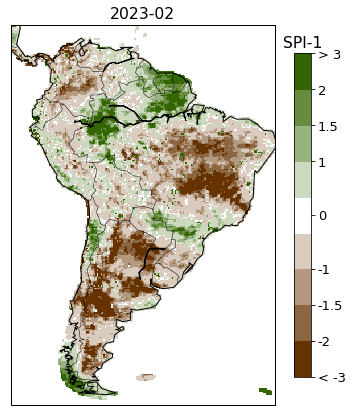

Processing SPI-1...


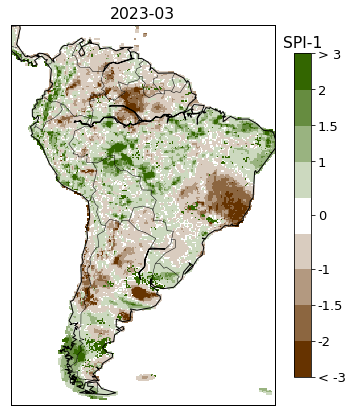

Processing SPI-1...


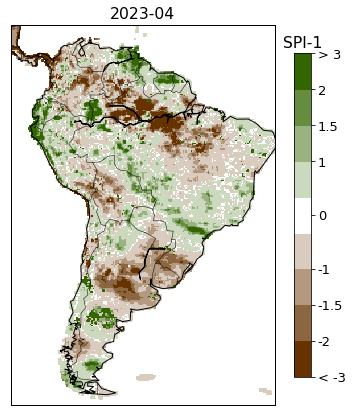

Processing SPI-1...


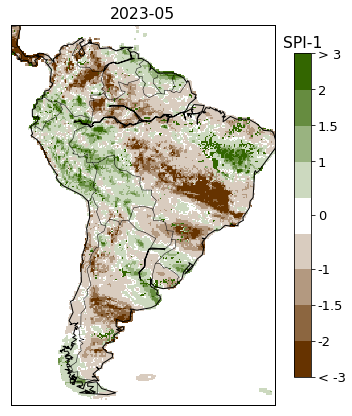

Processing SPI-1...


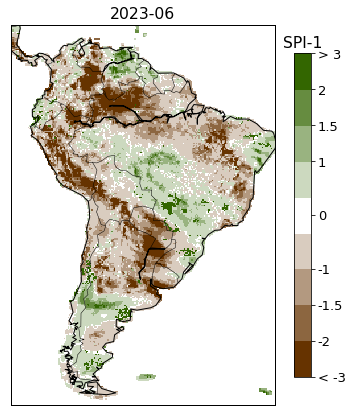

Processing SPI-1...


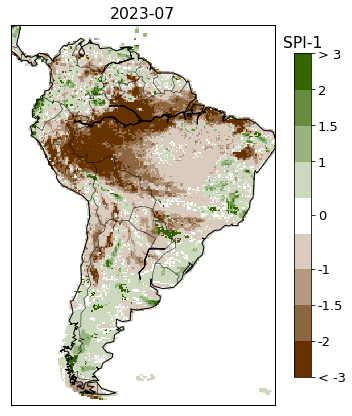

Processing SPI-1...


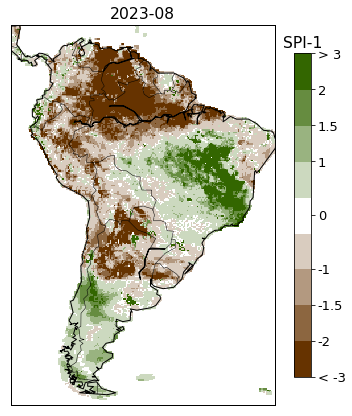

Processing SPI-1...


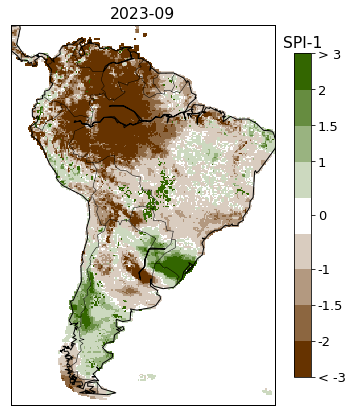

Processing SPI-1...


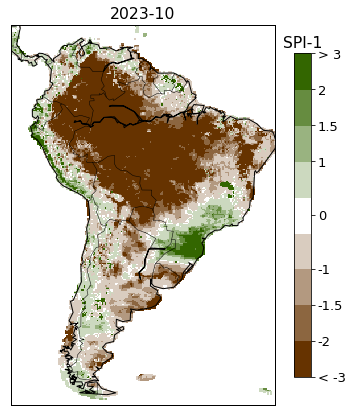

Processing SPI-12...


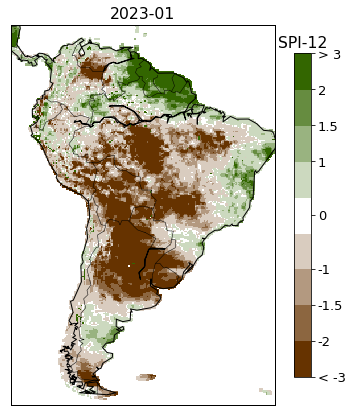

Processing SPI-12...


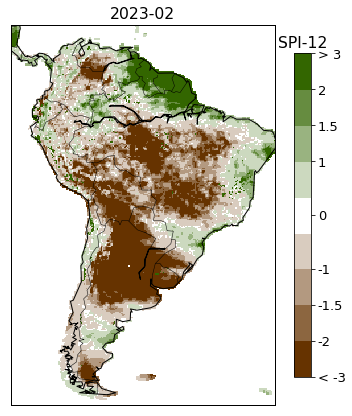

Processing SPI-12...


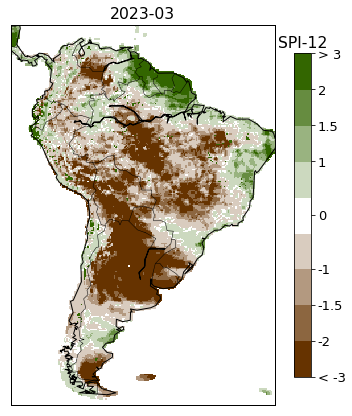

Processing SPI-12...


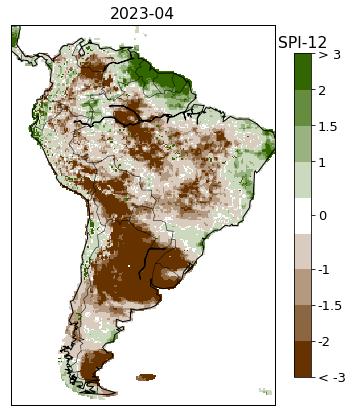

Processing SPI-12...


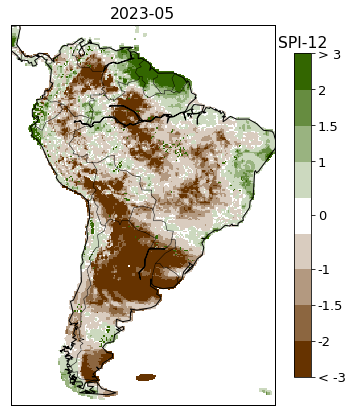

Processing SPI-12...


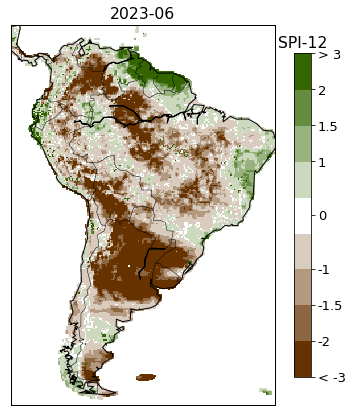

Processing SPI-12...


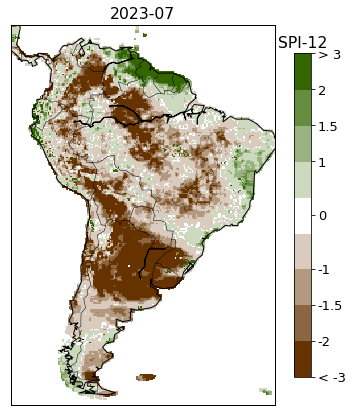

Processing SPI-12...


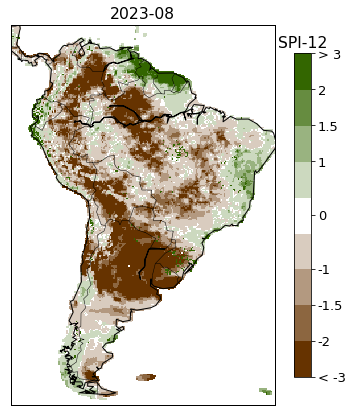

Processing SPI-12...


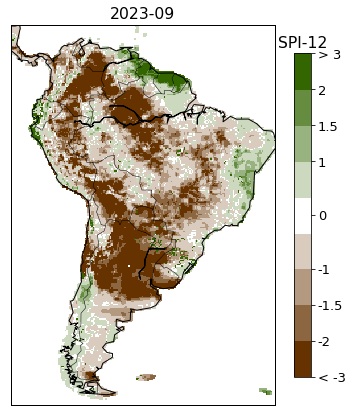

Processing SPI-12...


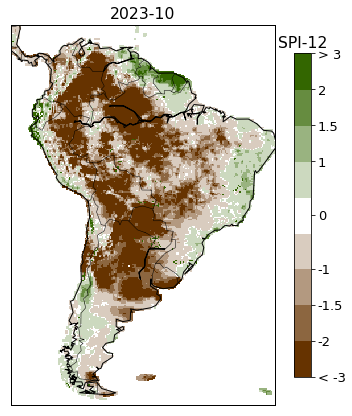

In [37]:
lats = np.asarray(spi1.lat)
lons = np.asarray(spi1.lon)
grid_lon, grid_lat = np.meshgrid(lons, lats)
    
for itime in range(len(spi1.time))[-10:]:

    print(f"Processing SPI-1...")

    stime = spi1.time.dt.strftime('%Y-%m').values[:][itime]
    ytime = spi1.time.dt.strftime('%Y').values[:][itime]

    # plot
    figname = f"figures/Droughtmap_SouthAmerica_SPI-1_{stime}.png"
    to_plot = np.asarray(spi1.sel(time=spi1.time[itime]).values[:])
    plot_droughtmap(grid_lon, grid_lat, to_plot, 
                    plot_type=plot_type,
                    xlim=[-85, -35], ylim=[-57, 15], zlim=[-3,3], 
                    xlab="",ylab="",
                    main_title=f"{stime}", legend_title=f"SPI-1", 
                    colorscheme=cmap_spi, levels=clevels, legend_ticks=[-3,-2,-1.5,-1,0,1,1.5,2,3], legend_ticklabels=["< -3",-2,-1.5,-1,0,1,1.5,2,"> 3"],
                    dfigsize=(7,7), figname=figname)

for itime in range(len(spi12.time))[-10:]:

    print(f"Processing SPI-12...")

    stime = spi12.time.dt.strftime('%Y-%m').values[:][itime]
    ytime = spi12.time.dt.strftime('%Y').values[:][itime]

    # plot
    figname = f"figures/Droughtmap_SouthAmerica_SPI-12_{stime}.png"
    to_plot = np.asarray(spi12.sel(time=spi12.time[itime]).values[:])
    plot_droughtmap(grid_lon, grid_lat, to_plot, 
                    plot_type=plot_type,
                    xlim=[-85, -35], ylim=[-57, 15], zlim=[-3,3], 
                    xlab="",ylab="",
                    main_title=f"{stime}", legend_title=f"SPI-12", 
                    colorscheme=cmap_spi, levels=clevels, legend_ticks=[-3,-2,-1.5,-1,0,1,1.5,2,3], legend_ticklabels=["< -3",-2,-1.5,-1,0,1,1.5,2,"> 3"],
                    dfigsize=(7,7), figname=figname)

    